# 06 · Choosing a baseline

A marine heatwave is defined against a baseline: the climatology and the threshold
that the temperature is compared with. With a warming ocean the choice changes the
answer. A fixed 1961–1990 baseline finds ever more heatwave days, because the ocean
has moved away from the past; a baseline that moves with the ocean finds about the
same share of days every decade, because it measures departures from the recent
normal. Neither is wrong: they answer different questions.

Smith et al. (2025, *Progress in Oceanography* 231, 103404) describe five baselines
and recommend reporting which one is used and why, and, where possible, how the
results depend on it (their recommendation 4c). xrMHW computes all five with
`xrMHW_clim(..., baseline=...)`:

| `baseline` | Reference | Answers |
|---|---|---|
| `"fixed"` | one period, e.g. 1961–1990 | change relative to a past state; impacts on systems that do not adapt |
| `"periodic"` | the 30 years before each decade, updated every 10 years (WMO normals) | departures from the current official normal |
| `"detrended"` | one period, after removing the long-term trend | variability around the trend; the trend is reported apart |
| `"shifting"` | the 30 years before each year | departures from the recent past, for systems that keep up with change |
| `"adaptation"` | a fixed threshold that rises at a given rate | impacts on an organism that adapts at that rate |

The notebook has two parts. First a synthetic series of 65 years whose warming
accelerates, like Smith et al.'s Box 1, where the five behave in clearly different
ways. Then a real series from the GLORYS12V1 example data, only 33 years long, where
the windows have to be shorter.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import xarray as xr

import xrMHW

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9,
    "axes.grid": True, "grid.color": "#e7e6e2", "grid.linewidth": 0.6,
})
INK, INK2 = "#0b0b0b", "#52514e"
# One colour per baseline, the same in every figure
COLORS = {"fixed": "#0b0b0b", "periodic": "#2a78d6", "detrended": "#1f9e74",
          "shifting": "#eb6834", "shifting, no detrending": "#eb6834",
          "adaptation": "#8a5cc2"}
STYLES = {"shifting, no detrending": ":"}
print("xrMHW", xrMHW.__version__)

xrMHW 3.0.0


## 1. A synthetic series with accelerating warming

65 years of daily temperature, 1961–2025: a seasonal cycle, persistent anomalies
(an AR(1) process with a 10-day memory, so that warm spells last several days) and a
warming that accelerates from almost nothing in the 1960s to about 0.5 °C per decade
at the end, 1.6 °C in total. The shape of the warming is known, which lets us check
each baseline against what it should do.

One series is noisy: a single decade can have twice the heatwave days of the next by
chance. So we make 50 independent series with the same warming, on a `cell`
dimension, and xrMHW treats each as its own grid cell.

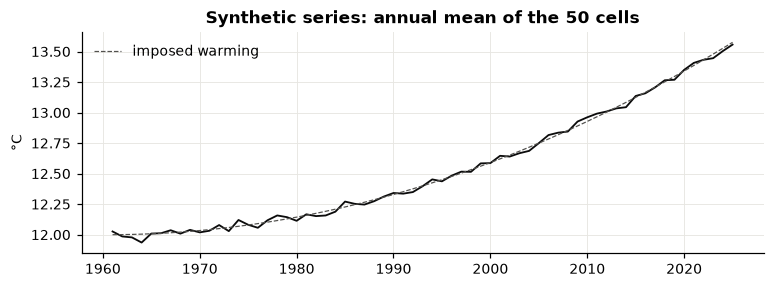

In [2]:
rng = np.random.default_rng(2025)
time = pd.date_range("1961-01-01", "2025-12-31", freq="D")
years = time.year + (time.dayofyear - 0.5) / 365.25
warming = 1.6 * ((years - 1961) / 65) ** 2               # accelerating, 1.6 degC in total
seasonal = 12 + 4 * np.sin(2 * np.pi * (time.dayofyear - 100) / 365.25)
phi, sd, n_cells = np.exp(-1 / 10), 0.6, 50              # 10-day memory, 0.6 degC std
noise = np.empty((len(time), n_cells))
noise[0] = rng.normal(0, sd, n_cells)
eps = rng.normal(0, sd * np.sqrt(1 - phi ** 2), (len(time), n_cells))
for i in range(1, len(time)):
    noise[i] = phi * noise[i - 1] + eps[i]
sst = np.asarray(seasonal + warming)[:, None] + noise
synth = xr.Dataset({"sst": (("time", "cell"), sst)},
                   coords={"time": time, "cell": np.arange(n_cells)})
synth["sst"].attrs["units"] = "degC"

fig, ax = plt.subplots(figsize=(8, 2.6))
annual = synth["sst"].mean("cell").groupby("time.year").mean()
ax.plot(annual["year"], annual, color=INK, lw=1.2)
ax.plot(annual["year"], 12 + 1.6 * ((annual["year"] + 0.5 - 1961) / 65) ** 2, color=INK2,
        lw=0.8, ls="--", label="imposed warming")
ax.set(title="Synthetic series: annual mean of the 50 cells", ylabel="°C")
ax.legend(frameon=False)
plt.show()

## 2. The five baselines

Each baseline is one call to `xrMHW_clim`; `xrMHW_events` then applies it. The
options:

* **fixed**: 1961–1990, the classic reference.
* **periodic**: the WMO practice: each decade uses the 30 years before it
  (2021–2030 uses 1991–2020). The decades before 1991 have no complete 30-year
  period before them, so they use the first one in the record, 1961–1990, and a
  warning says so.
* **detrended**: the trend of the anomaly is removed over the whole record before
  the 1961–1990 climatology is computed, then added back to the climatology and the
  threshold. The trend must have the right shape: here a quadratic, because the
  warming accelerates (`trend="polynomial", degree=2`).
* **shifting**: each year uses the 30 years before it. By default the trend is
  removed first (`detrend_first=True`, Smith et al.'s recommendation 3e), here as a
  quadratic too. We also run it without removing the trend, to see why that
  recommendation exists.
* **adaptation**: the 1961–1990 threshold rising at 0.15 °C per decade from the
  centre of the period, for an organism that adapts at that rate.

The warnings below are expected: they list the years that fall back to the first
complete window.

In [3]:
SYNTH_BASELINES = {
    "fixed": dict(baseline="fixed", clim_period=(1961, 1990)),
    "periodic": dict(baseline="periodic"),
    "detrended": dict(baseline="detrended", clim_period=(1961, 1990),
                      trend="polynomial", degree=2),
    "shifting": dict(baseline="shifting", trend="polynomial", degree=2),
    "shifting, no detrending": dict(baseline="shifting", detrend_first=False),
    "adaptation": dict(baseline="adaptation", clim_period=(1961, 1990), rate=0.15),
}
OUTPUTS = ["intensity", "severity", "duration", "climatology", "threshold"]


def run_baselines(ds, var, baselines):
    events, annual = {}, {}
    for name, kw in baselines.items():
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            clim = xrMHW.xrMHW_clim(ds, var, **kw)
        for w in caught:
            print(f"{name}: {w.message}")
        events[name] = xrMHW.xrMHW_events(ds, var, clim, output_vars=OUTPUTS)
        annual[name] = xrMHW.xrMHW_annual(events[name])
    return events, annual


synth_events, synth_annual = run_baselines(synth, "sst", SYNTH_BASELINES)

periodic: No complete 30-year reference period before the periods starting in [1961, 1971, 1981]; they use the first complete one, (1961, 1990), which makes them a fixed baseline (an approximation).


shifting: No complete 30-year lagged window for the years 1961-1990; they use the nearest complete window in the record, which makes them a fixed baseline (an approximation).


shifting, no detrending: No complete 30-year lagged window for the years 1961-1990; they use the nearest complete window in the record, which makes them a fixed baseline (an approximation).


### What each threshold looks like

The annual mean of each threshold shows how it follows (or does not follow) the
warming:

* the **fixed** threshold stays where 1961–1990 put it;
* the **periodic** one moves in steps, from 2001, when the first 30-year period
  inside the record ends;
* the **detrended** one follows the fitted trend;
* the **shifting** one, with the trend removed first, follows the same curve: once
  the trend is removed nothing is left for a moving window to follow, so the two
  lines overlap (dashed over solid). Without removing the trend (dotted) it lags the
  warming, because each year is measured against the 30 years before it;
* the **adaptation** one rises in a straight line from the centre of 1961–1990.

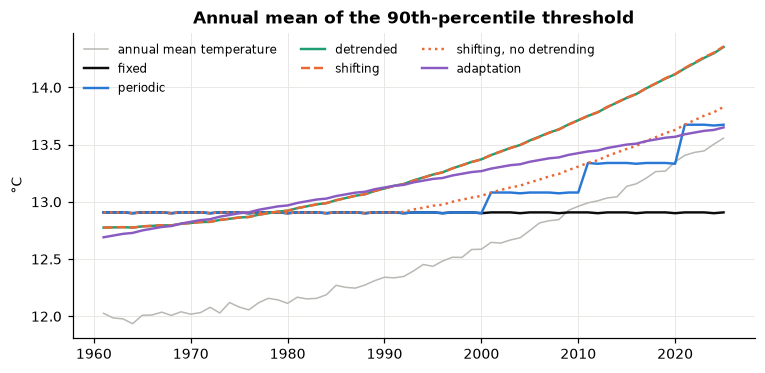

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(annual["year"], annual, color="#b9b8b4", lw=1, label="annual mean temperature")
THR_STYLES = {"shifting": "--", "shifting, no detrending": ":"}
for name, ev in synth_events.items():
    thr = ev["mhw_threshold"].mean("cell").groupby("time.year").mean()
    ax.plot(thr["year"], thr, color=COLORS[name], lw=1.6, ls=THR_STYLES.get(name, "-"),
            label=name)
ax.set(title="Annual mean of the 90th-percentile threshold", ylabel="°C")
ax.legend(frameon=False, ncol=3, fontsize=8)
plt.show()

### Share of days in a heatwave, decade by decade

With a 90th-percentile threshold about 10 % of days are above it in the reference
period, and a little less in heatwaves, because short exceedances (under 5 days) do
not count. Smith et al.'s Box 1 judges a baseline by this share over time.
`xrMHW_annual` gives the event days of each year (`mhw_days`) and the days of the
record (`mhw_ndays`), so the share per decade is a ratio of sums, here over the 50
cells as well.

In [5]:
def share_by_decade(annual):
    rows = {}
    for name, ann in annual.items():
        decade = (ann["year"] // 10) * 10
        cells = [d for d in ann["mhw_days"].dims if d != "year"]
        n = int(np.prod([ann.sizes[d] for d in cells]))
        days = ann["mhw_days"].sum(cells).groupby(decade).sum()
        ndays = n * ann["mhw_ndays"].groupby(decade).sum()
        rows[name] = (100 * days / ndays).to_series()
    table = pd.DataFrame(rows).T
    table.columns = [f"{c}s" for c in table.columns]
    return table.round(1)


synth_share = share_by_decade(synth_annual)
synth_share

,1960s,1970s,1980s,1990s,2000s,2010s,2020s
fixed,3.4,4.7,7.5,16.2,32.5,57.0,78.1
periodic,3.4,4.7,7.5,16.2,23.4,29.6,32.5
detrended,5.2,5.5,5.2,5.6,6.1,5.8,5.7
shifting,5.2,5.5,5.2,5.6,6.2,5.7,5.6
"shifting, no detrending",3.4,4.7,7.5,13.8,18.1,21.5,25.4
adaptation,6.2,4.9,4.4,6.5,11.1,19.6,32.6


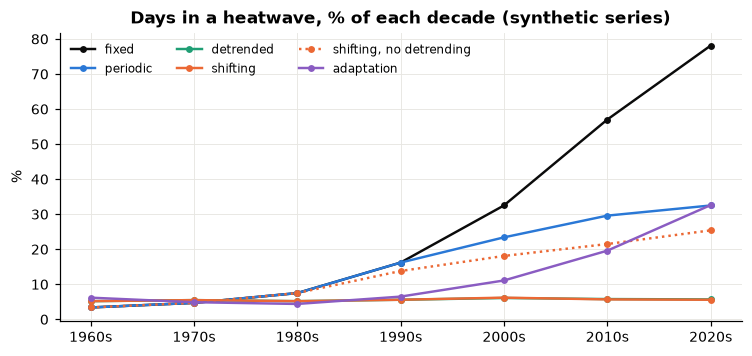

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(synth_share.shape[1])
for name, row in synth_share.iterrows():
    ax.plot(x, row.values, marker="o", ms=3.5, lw=1.6, color=COLORS[name],
            ls=STYLES.get(name, "-"), label=name)
ax.set_xticks(x, synth_share.columns)
ax.set(title="Days in a heatwave, % of each decade (synthetic series)", ylabel="%")
ax.legend(frameon=False, ncol=3, fontsize=8)
plt.show()

What the table shows:

* **Fixed**: from 3–8 % of days in the reference decades to 78 % in the 2020s. By
  then most days are warmer than the warm spells of 1961–1990: a statement about how
  far the ocean has moved, rather than about extremes.
* **Detrended** and **shifting** (trend removed first): 5–6 % in every decade. They
  measure departures from the trend, and with the right trend shape that share does
  not change. With a linear trend on this accelerating warming, the residual is
  warm at both ends and too many events appear there (Smith et al., Box 1), so the
  shape of the trend has to be chosen with care.
* **Shifting without removing the trend**: from 14 % in the 1990s to 25 % in the
  2020s. Each year is compared with 30 years that were cooler, because the ocean
  warmed during them; Smith et al.'s recommendation 3e, to remove the trend first,
  avoids it.
* **Periodic**: rises in steps, to 32 % in the 2020s, less than fixed because its
  reference is updated every decade.
* **Adaptation** at 0.15 °C per decade: steady while the warming is slower than
  that, then up to 33 % once it is faster (here from the 2000s). It counts
  heatwaves only for organisms that adapt at that rate.

The steady share is 5–6 % rather than 10 % because a heatwave needs at least 5
consecutive days above the 90th percentile; isolated warm days do not count.

## 3. A real series: the GLORYS12V1 example

The surface of one water column on the slope of the Grand Bank of Newfoundland (the
same cell as notebook 01), 1993-01-01 to 2025-11-25. With 33 years there is no room
for 30-year windows that move: a 30-year shifting or periodic baseline would give
almost every year the same first window, 1993–2022. So here the moving baselines use
**20 years**, shorter than the WMO's 30, which makes their percentiles less stable;
the fixed and detrended ones keep 1993–2022. The adaptation rate, 0.2 °C per decade,
is only an example.

In [7]:
EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("xrmhw"),
    base_url="doi:10.5281/zenodo.22909109/",
    registry={
        "xrmhw_glorys_4d_subset.nc": "md5:5555737e45f1c6cde9f657e50f456693",
        "xrmhw_ostia_sst_3d.nc": "md5:74a2da227394e4463f203f6b388518ee",
    },
)
glorys = xr.open_dataset(EXAMPLE_DATA.fetch("xrmhw_glorys_4d_subset.nc"))
surface = (glorys.sel(latitude=44.0, longitude=-48.75, method="nearest")
           .isel(depth=0).load())
print(f"{float(surface.latitude):.3f}°N, {-float(surface.longitude):.3f}°W, "
      f"{float(surface.depth):.2f} m, {surface.sizes['time']} days")

GLORYS_BASELINES = {
    "fixed": dict(baseline="fixed", clim_period=(1993, 2022)),
    "periodic": dict(baseline="periodic", ref_length=20, update_every=5),
    "detrended": dict(baseline="detrended", clim_period=(1993, 2022)),
    "shifting": dict(baseline="shifting", window=20),
    "adaptation": dict(baseline="adaptation", clim_period=(1993, 2022), rate=0.2),
}
glorys_events, glorys_annual = run_baselines(surface, "thetao", GLORYS_BASELINES)

44.000°N, 48.750°W, 0.49 m, 12017 days
periodic: No complete 20-year reference period before the periods starting in [1991, 1996, 2001, 2006, 2011]; they use the first complete one, (1993, 2012), which makes them a fixed baseline (an approximation).


shifting: No complete 20-year lagged window for the years 1993-2012; they use the nearest complete window in the record, which makes them a fixed baseline (an approximation).


The warnings matter here: with 20-year windows the shifting baseline only has a
threshold of its own from 2013 and the periodic one from 2016; before that they
repeat the first window and behave like a fixed 1993–2012 baseline.

### Heatwave days per year, and their trend

2025 is incomplete (it ends on 25 November), so the figure shows the share of days
and the trend uses 1993–2024. `xrMHW_trend` gives the Theil-Sen slope with its 95 %
confidence interval and the Mann-Kendall p-value.

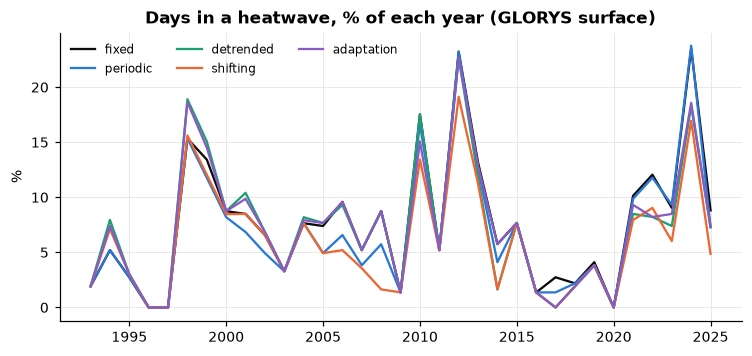

,mean days per year,trend (days/decade),95 % CI low,95 % CI high,p (Mann-Kendall)
baseline,,,,,
fixed,27.781,3.846,-5.333,12.692,0.322
periodic,25.500,3.485,-4.583,12.222,0.363
detrended,26.562,0.000,-8.571,8.462,0.961
shifting,22.406,0.000,-7.500,7.857,0.884
adaptation,26.906,1.062,-7.778,9.643,0.733


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for name, ann in glorys_annual.items():
    share = 100 * ann["mhw_days"] / ann["mhw_ndays"]
    ax.plot(ann["year"], share, color=COLORS[name], lw=1.5, label=name)
ax.set(title="Days in a heatwave, % of each year (GLORYS surface)", ylabel="%")
ax.legend(frameon=False, ncol=3, fontsize=8)
plt.show()

rows = []
for name, ann in glorys_annual.items():
    tr = xrMHW.xrMHW_trend(ann["mhw_days"].sel(year=slice(1993, 2024)))
    rows.append({"baseline": name,
                 "mean days per year": float(ann["mhw_days"].sel(year=slice(1993, 2024)).mean()),
                 "trend (days/decade)": float(tr["slope"]),
                 "95 % CI low": float(tr["slope_low"]),
                 "95 % CI high": float(tr["slope_high"]),
                 "p (Mann-Kendall)": float(tr["p_value"])})
glorys_trends = pd.DataFrame(rows).set_index("baseline").round(3)
glorys_trends

In this cell the baselines differ much less than in the synthetic series. Over 33
years the surface warming is small next to the year-to-year variability, and the
heatwave days come mostly from a few years (1998, 2010, 2012 and 2024 stand out
under every baseline).

* The shifting baseline gives the fewest days, about 22 a year against 25–28. It
  differs even before 2013, because its first window is 1993–2012, not 1993–2022,
  and the trend is removed first.
* No trend is significant: every p-value is above 0.3 and every confidence interval
  contains zero. The detrended and shifting slopes are exactly 0: pairs of years
  with the same number of heatwave days have a slope of exactly zero, and with
  counts like these the median often falls on one of them.

With 33 years and 20-year windows these differences are within the noise. They are
still worth reporting (Smith et al., recommendation 4c), but conclusions about
trends need longer records or many cells.

### When in the year

`xrMHW_monthly` gives the same quantities per month. Averaging the monthly event
days over the years shows the season of the heatwaves under each baseline.

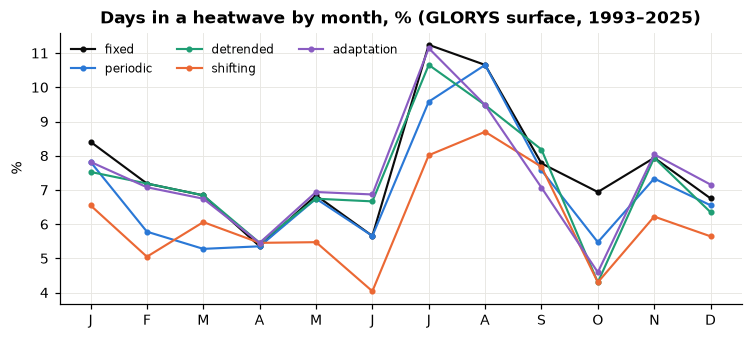

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for name, ev in glorys_events.items():
    mon = xrMHW.xrMHW_monthly(ev)
    share = 100 * (mon["mhw_days"] / mon["mhw_ndays"]).groupby("month").mean()
    ax.plot(share["month"], share, marker="o", ms=3, color=COLORS[name], lw=1.4, label=name)
ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set(title="Days in a heatwave by month, % (GLORYS surface, 1993–2025)", ylabel="%")
ax.legend(frameon=False, ncol=3, fontsize=8)
plt.show()

## 4. Which baseline to use

* Say which baseline you used and why; the numbers depend on it.
* For **impacts on systems that do not adapt** (for example corals near their
  thermal limit, or infrastructure), a **fixed** baseline measures the exposure.
* To separate **variability from the long-term trend**, use **detrended**, with a
  trend shape that fits the data, and report the trend apart.
* For **systems that keep up with change**, use **shifting** (with the trend removed
  first) or **adaptation** with a rate you can justify.
* **Periodic** follows the official climate normals, which makes results comparable
  with other climate products, at the cost of jumps when the normal is updated.
* Moving windows need long records: with fewer than about 40 years, a 30-year
  window leaves almost no years with a baseline of their own.

Smith et al. (2025) recommend reporting results under more than one baseline when
the choice is not obvious; with xrMHW that is one `xrMHW_clim` call per baseline,
as above.

**Reference:** Smith, K. E., et al. (2025). Baseline matters: Challenges and
implications of different marine heatwave baselines. *Progress in Oceanography*,
231, 103404. https://doi.org/10.1016/j.pocean.2024.103404